In [8]:
# ДЗ 6
# преобразование Хаара (3 ступени)

In [9]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

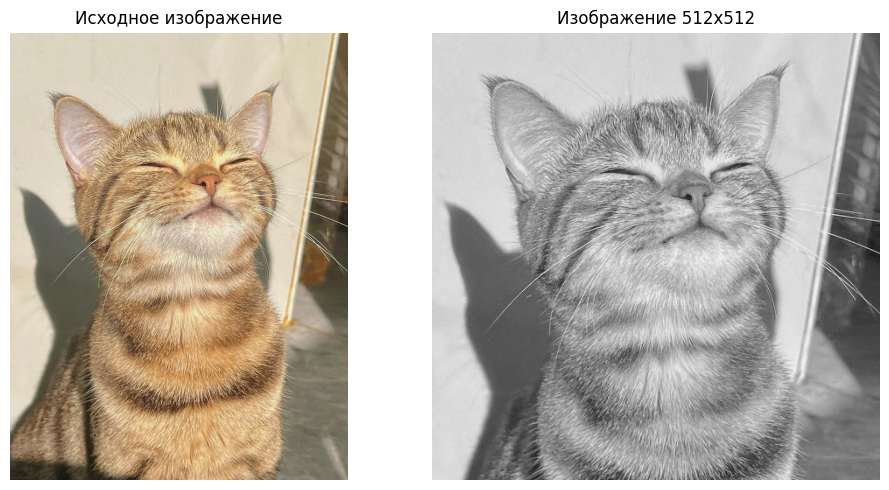

In [10]:
image = cv2.imread('IMG_0846.JPG')

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

height, width = image_gray.shape
side = min(height, width)
x0 = (width - side) // 2
y0 = (height - side) // 4
image_square = image_gray[y0:y0 + side, x0:x0 + side]
image_512 = cv2.resize(image_square, (512, 512), interpolation=cv2.INTER_AREA)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('Исходное изображение')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(image_512, cmap='gray', vmin=0, vmax=255)
plt.title('Изображение 512x512')
plt.axis('off')
plt.tight_layout()
plt.show()

## Преобразование Хаара

In [11]:
# LL (приближение), LH (вертикальные границы), HL (горизонтальные границы), HH (диагонали)
def haar_level(img):
    img = img.astype(np.float64)
    L = (img[:, 0::2] + img[:, 1::2]) / 2
    H = (img[:, 0::2] - img[:, 1::2]) / 2
    LL = (L[0::2, :] + L[1::2, :]) / 2
    HL = (L[0::2, :] - L[1::2, :]) / 2
    LH = (H[0::2, :] + H[1::2, :]) / 2
    HH = (H[0::2, :] - H[1::2, :]) / 2
    return LL, LH, HL, HH

## Три ступени преобразования Хаара

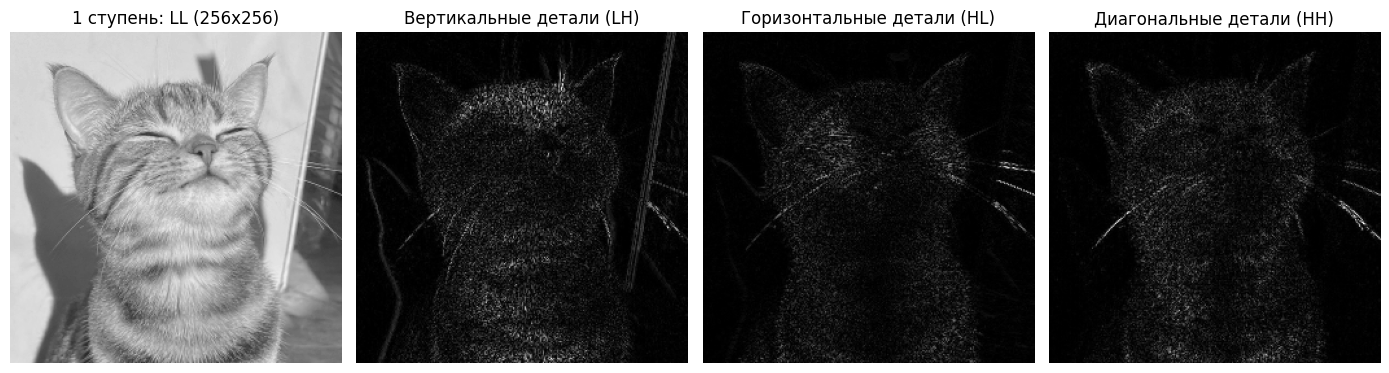

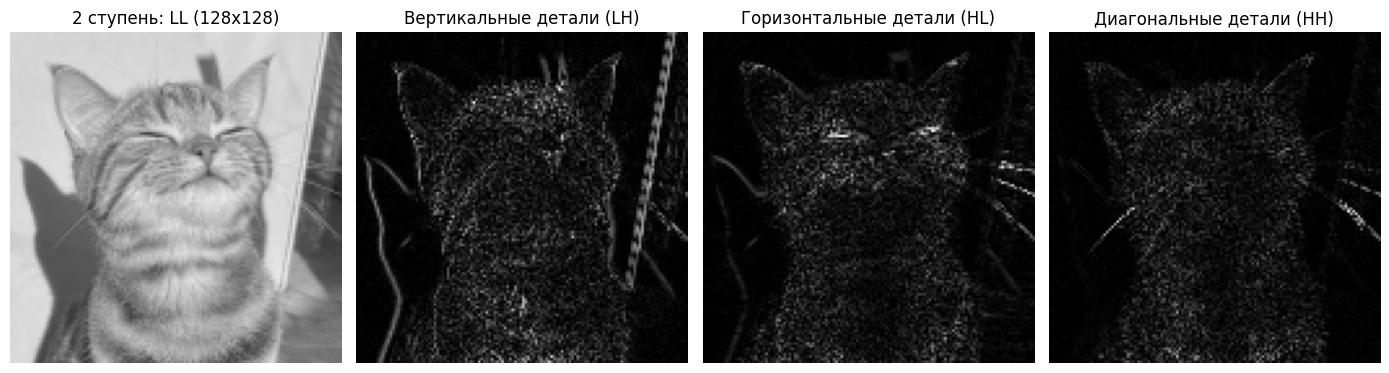

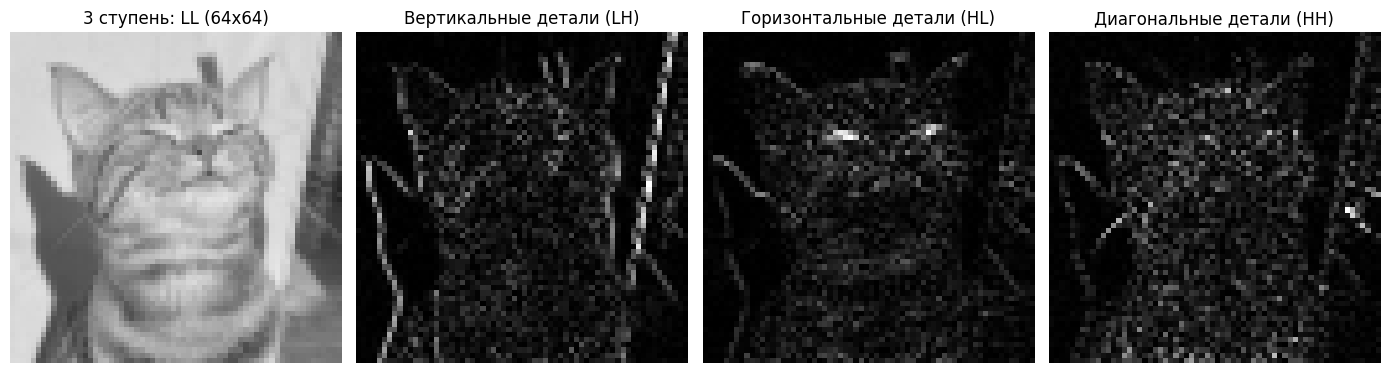

In [12]:
current = image_512.astype(np.float64)
levels = []
for i in range(3):
    LL, LH, HL, HH = haar_level(current)
    levels.append((LL, LH, HL, HH))
    current = LL

for i, (LL, LH, HL, HH) in enumerate(levels, start=1):
    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    axes[0].imshow(LL, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title(f'{i} ступень: LL ({LL.shape[0]}x{LL.shape[1]})')
    axes[1].imshow(np.abs(LH), cmap='gray', vmin=0)
    axes[1].set_title('Вертикальные детали (LH)')
    axes[2].imshow(np.abs(HL), cmap='gray', vmin=0)
    axes[2].set_title('Горизонтальные детали (HL)')
    axes[3].imshow(np.abs(HH), cmap='gray', vmin=0)
    axes[3].set_title('Диагональные детали (HH)')

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()

## Сравнение ступеней сжатия

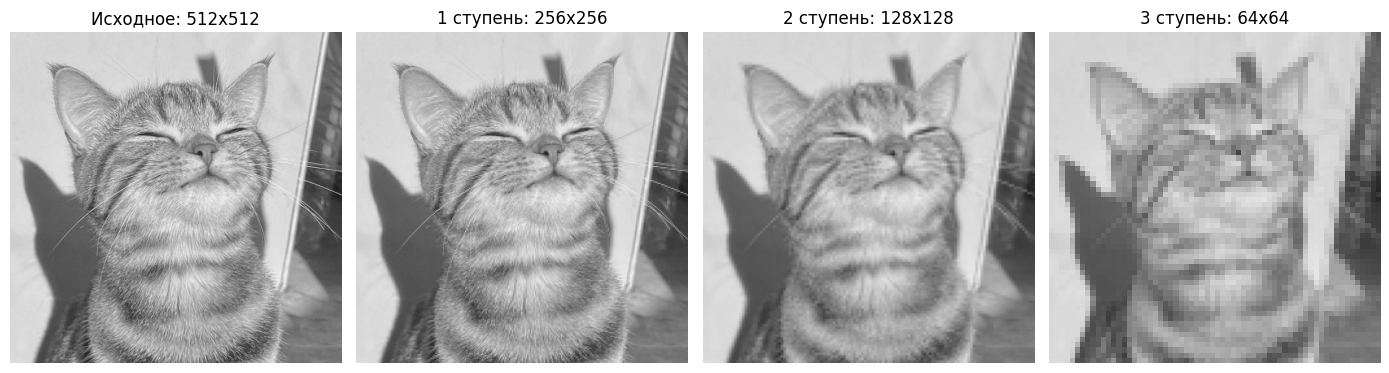

In [13]:
LL1 = levels[0][0]
LL2 = levels[1][0]
LL3 = levels[2][0]
images = [image_512, LL1, LL2, LL3]
titles = ['Исходное: 512x512', '1 ступень: 256x256', '2 ступень: 128x128', '3 ступень: 64x64']

plt.figure(figsize=(14, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

## Результат сжатия после третьей ступени

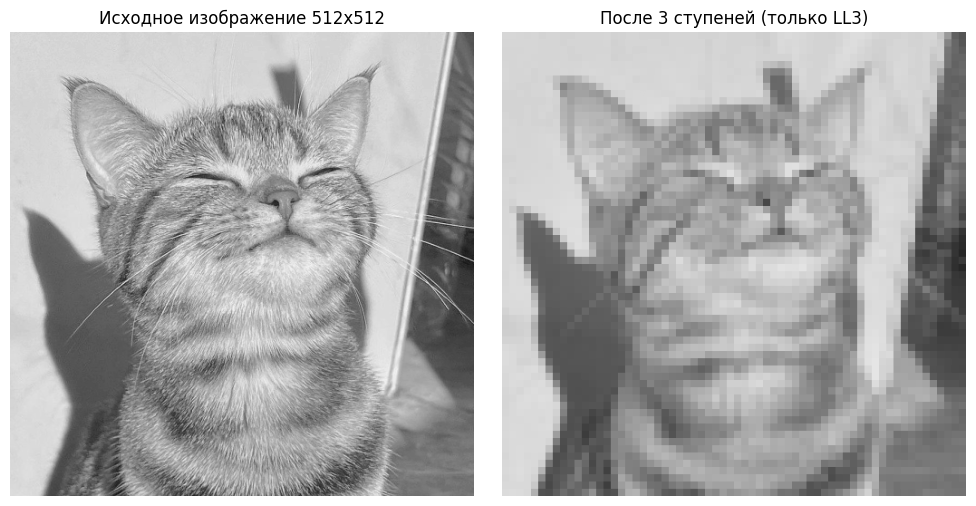

In [14]:
compressed = LL3

restored = cv2.resize(compressed, (512, 512), interpolation=cv2.INTER_NEAREST)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_512, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение 512x512')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
plt.title('После 3 ступеней (только LL3)')
plt.axis('off')

plt.tight_layout()
plt.show()

# После трёх ступеней преобразования Хаара изображение теряет мелкие детали